# Task 18 - Categorical Encoding with High-Cardinality Handling

**Goal:** one-hot encode categorical variables without feature explosion, using **target encoding**, **frequency-based binning** and **dimensionality reduction**, while keeping the result interpretable.

**Input:** newest available dataset in `data/processed/` (Task 17 output preferred)
**Outputs:** `data/processed/womens_clothing_high_cardinality_encoded.csv`, `reports/task_18_encoding_plan.csv`, `reports/task_18_target_encoding_map.csv`, `reports/task_18_analysis_status.csv`

**Strategy by cardinality (all thresholds configurable)**

| Unique levels | Treatment |
|---|---|
| <= 10 | plain one-hot (`oh_<col>_<level>`) |
| 11 - 50 | frequency-based binning (levels under 2% -> `Other`), then one-hot, plus a target-encoded column |
| > 50 | target encoding (smoothed, out-of-fold) + frequency encoding + SVD components of the binned one-hot |

Free-text columns (reviews, titles) and obvious identifiers are excluded. Original columns are kept untouched so the dataset stays interpretable; the new columns are all prefixed (`oh_`, `te_`, `fe_`, `svd_`).

In [1]:
import re, warnings
from pathlib import Path
from datetime import datetime
import numpy as np
import pandas as pd
warnings.filterwarnings("ignore")

def find_project_root():
    """Walk up from the notebook folder until a folder containing data/processed is found."""
    start = Path.cwd().resolve()
    for cand in [start, *start.parents]:
        if (cand / "data" / "processed").exists():
            return cand
    return start.parent

ROOT = find_project_root()
PROC = ROOT / "data" / "processed"
REPORTS = ROOT / "reports"
PROC.mkdir(parents=True, exist_ok=True)
REPORTS.mkdir(parents=True, exist_ok=True)
print("Project root:", ROOT)

def _norm(s):
    return re.sub(r"[^a-z0-9]", "", str(s).lower())

def pick(df, *candidates, required=True):
    """Return the real column name matching any candidate (ignores case, spaces, underscores)."""
    lookup = {_norm(c): c for c in df.columns}
    for cand in candidates:
        if _norm(cand) in lookup:
            return lookup[_norm(cand)]
    if required:
        raise KeyError(f"None of {candidates} found. Columns: {list(df.columns)}")
    return None

def load_first(*paths, require_any=None):
    """Load the first existing CSV (optionally one that has at least one of the required columns)."""
    for p in paths:
        if not Path(p).exists():
            continue
        d = pd.read_csv(p)
        d = d.loc[:, ~d.columns.str.startswith("Unnamed")]
        if require_any and not any(_norm(c) in {_norm(x) for x in d.columns} for c in require_any):
            print(f"Skipped {Path(p).name}: none of {require_any} present")
            continue
        print(f"Loaded: {Path(p).name}  shape={d.shape}")
        return d, Path(p)
    raise FileNotFoundError("No usable file found among: " + ", ".join(str(p) for p in paths))

# Newest cumulative dataset first; each task falls back to an earlier file if a later one does not exist yet.
CHAIN = ["womens_clothing_high_cardinality_encoded.csv", "womens_clothing_engagement_features.csv",
         "womens_clothing_sentiment_features.csv", "womens_clothing_age_segmented.csv",
         "womens_clothing_review_text_features.csv", "womens_clothing_market_basket_features.csv",
         "womens_clothing_product_text_features.csv", "womens_clothing_product_tag_features.csv",
         "womens_clothing_product_segmented.csv", "womens_clothing_final.csv"]

import matplotlib.pyplot as plt
import seaborn as sns
from scipy import sparse
from sklearn.decomposition import TruncatedSVD
from sklearn.model_selection import KFold, StratifiedKFold, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 60)
RANDOM_STATE = 42

# ---------------- configuration ----------------
LOW_MAX, MID_MAX = 10, 50        # cardinality boundaries
RARE_SHARE = 0.02                # levels below this share are binned to "Other"
SMOOTHING = 20                   # target-encoding smoothing strength
SVD_COMPONENTS = 5               # per high-cardinality column
N_FOLDS = 5

Project root: D:\OneDrive\Desktop\Brainybeams\Womens_Clothing_ML_Project


## 1. Load data and choose the target

In [2]:
candidates = [PROC / n for n in CHAIN]
candidates += sorted(PROC.glob("*.csv"), reverse=True)
candidates += [ROOT / "data" / "interim" / "womens_clothing_standardized.csv",
               ROOT / "data" / "interim" / "womens_clothing_cleaned.csv",
               ROOT / "data" / "raw" / "womens_clothing.csv"]
df, src = load_first(*candidates)
rating_col = pick(df, "Rating")
rec_col    = pick(df, "Recommended IND", "Recommended", required=False)
y = df[rec_col].astype(int) if rec_col else (df[rating_col] >= 4).astype(int)
target_name = rec_col or "Rating >= 4"
print("Target for encoding / evaluation:", target_name, "| positive share:", round(y.mean(), 3))

# columns that must never be used as encoding inputs (text, ids, derived from the target)
TEXT_LIKE = {"reviewtext", "review", "title", "sentimenttext"}
# Clothing ID is numeric but categorical in meaning
id_like = pick(df, "Clothing ID", "ClothingID", "Product ID", required=False)
cand = [c for c in df.columns if df[c].dtype == object or str(df[c].dtype) in ("string", "category", "str") or c == id_like]
cand = [c for c in cand if re.sub(r"[^a-z]", "", c.lower()) not in TEXT_LIKE]
# drop columns that are effectively free text (long strings) or unique per row
def avg_len(c): return df[c].astype("string").str.len().mean()
cand = [c for c in cand if 2 <= df[c].nunique() < 0.5 * len(df) and avg_len(c) < 40]   # skip constants and free text
plan = pd.DataFrame({"column": cand, "n_unique": [df[c].nunique() for c in cand], "missing": [df[c].isna().sum() for c in cand]})
plan["strategy"] = np.select([plan["n_unique"] <= LOW_MAX, plan["n_unique"] <= MID_MAX], ["one-hot", "bin + one-hot + target"], "target + frequency + SVD")
plan.sort_values("n_unique")

Loaded: womens_clothing_engagement_features.csv  shape=(1539, 76)
Target for encoding / evaluation: Rating >= 4 | positive share: 0.379


,column,n_unique,missing,strategy
3,urgency_text,2,1071,one-hot
5,sentiment_label,3,0,one-hot
6,engagement_level,3,0,one-hot
4,origin_country,6,16,one-hot
2,shipping_option_name,15,0,bin + one-hot + target
0,product_color,101,41,target + frequency + SVD
1,product_variation_size_id,106,14,target + frequency + SVD


In [3]:
# What naive one-hot would cost
naive_width = int(sum(df[c].nunique() for c in cand))
print("Naive one-hot width:", naive_width, "columns")

Naive one-hot width: 236 columns


## 2. Encoders

- **Frequency binning:** levels with share under `RARE_SHARE` become `Other`.
- **Target encoding:** smoothed mean `(n*mean_level + m*global) / (n + m)`. Training rows get **out-of-fold** values (K-fold) so a row's own label never feeds its encoding; the full-data map is saved for scoring new data.
- **Frequency encoding:** share of rows with that level.
- **SVD:** truncated SVD on the sparse one-hot of binned levels compresses a high-cardinality column into a few dense components.

In [4]:
def bin_rare(s, share=RARE_SHARE):
    s = s.astype("string").fillna("Missing")
    freq = s.value_counts(normalize=True)
    keep = set(freq[freq >= share].index)
    return s.where(s.isin(keep), "Other")

def target_encode_oof(s, y, m=SMOOTHING, n_splits=N_FOLDS):
    s = s.astype("string").fillna("Missing"); g = y.mean(); out = pd.Series(np.nan, index=s.index)
    for tr, va in StratifiedKFold(n_splits, shuffle=True, random_state=RANDOM_STATE).split(s, y):
        st = y.iloc[tr].groupby(s.iloc[tr]).agg(["sum", "count"])
        enc = (st["sum"] + m * g) / (st["count"] + m)
        out.iloc[va] = s.iloc[va].map(enc).fillna(g).values
    return out

def target_encode_full(s, y, m=SMOOTHING):
    s = s.astype("string").fillna("Missing"); g = y.mean()
    st = y.groupby(s).agg(["sum", "count"])
    return ((st["sum"] + m * g) / (st["count"] + m)).rename("te_value").to_frame().assign(n=st["count"], global_mean=g).rename_axis("level")

## 3. Apply the strategy

In [5]:
blocks, te_maps, rows = [], [], []
svd_info = {}
for _, r in plan.iterrows():
    c, k = r["column"], r["n_unique"]; tag = re.sub(r"[^A-Za-z0-9]+", "_", c).strip("_").lower()
    s = df[c]
    if k <= LOW_MAX:
        oh = pd.get_dummies(s.astype("string").fillna("Missing"), prefix=f"oh_{tag}", dtype=int)
        blocks.append(oh); n_new = oh.shape[1]; made = "one-hot"
    elif k <= MID_MAX:
        b = bin_rare(s)
        oh = pd.get_dummies(b, prefix=f"oh_{tag}", dtype=int)
        te = target_encode_oof(s, y).rename(f"te_{tag}")
        blocks += [oh, te]; te_maps.append(target_encode_full(s, y).reset_index().assign(column=c))
        n_new = oh.shape[1] + 1; made = f"binned ({b.nunique()} levels) one-hot + target"
    else:
        b = bin_rare(s, share=0.001)                       # keep fine detail for SVD, only drop singletons
        X = sparse.csr_matrix(pd.get_dummies(b, dtype=np.int8).values.astype(float))
        n_comp = int(min(SVD_COMPONENTS, X.shape[1] - 1))
        svd = TruncatedSVD(n_comp, random_state=RANDOM_STATE).fit(X)
        comps = pd.DataFrame(svd.transform(X), index=df.index, columns=[f"svd_{tag}_{i + 1}" for i in range(n_comp)])
        te = target_encode_oof(s, y).rename(f"te_{tag}")
        fe = s.astype("string").fillna("Missing").map(s.astype("string").fillna("Missing").value_counts(normalize=True)).rename(f"fe_{tag}")
        blocks += [te, fe, comps]; te_maps.append(target_encode_full(s, y).reset_index().assign(column=c))
        svd_info[c] = svd.explained_variance_ratio_.sum(); n_new = 2 + n_comp
        made = f"target + frequency + {n_comp} SVD comps (explain {svd_info[c]:.0%} of binned one-hot variance)"
    rows.append({"column": c, "n_unique": k, "strategy": r["strategy"], "applied": made, "new_columns": n_new})

encoded = pd.concat(blocks, axis=1)
plan_out = pd.DataFrame(rows)
print(f"Encoded width: {encoded.shape[1]} columns vs naive one-hot {naive_width} ({encoded.shape[1] / naive_width:.1%})")
plan_out

Encoded width: 33 columns vs naive one-hot 236 (14.0%)


,column,n_unique,strategy,applied,new_columns
0,product_color,101,target + frequency + SVD,target + frequency + 5 SVD comps (explain 51% ...,7
1,product_variation_size_id,106,target + frequency + SVD,target + frequency + 5 SVD comps (explain 82% ...,7
2,shipping_option_name,15,bin + one-hot + target,binned (2 levels) one-hot + target,3
3,urgency_text,2,one-hot,one-hot,3
4,origin_country,6,one-hot,one-hot,7
5,sentiment_label,3,one-hot,one-hot,3
6,engagement_level,3,one-hot,one-hot,3


## 4. Does the compressed encoding keep the signal? (leak-aware check)

In [6]:
# Compare logistic regression on (a) naive one-hot of all candidate columns vs (b) the engineered columns.
# Target-encoded columns are out-of-fold, so this comparison is not inflated by leakage.
cv = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
naive = sparse.hstack([sparse.csr_matrix(pd.get_dummies(df[c].astype("string").fillna("Missing"), dtype=np.int8).values.astype(float)) for c in cand]).tocsr()
auc_naive = cross_val_score(LogisticRegression(max_iter=2000, C=0.5), naive, y, cv=cv, scoring="roc_auc")
auc_eng = cross_val_score(make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, C=0.5)), encoded.values, y, cv=cv, scoring="roc_auc")
check = pd.DataFrame({"representation": ["naive one-hot", "engineered (this task)"], "n_features": [naive.shape[1], encoded.shape[1]],
                      "cv_auc_mean": [auc_naive.mean(), auc_eng.mean()], "cv_auc_std": [auc_naive.std(), auc_eng.std()]}).round(4)
check

,representation,n_features,cv_auc_mean,cv_auc_std
0,naive one-hot,240,0.5922,0.0161
1,engineered (this task),33,0.5929,0.0180


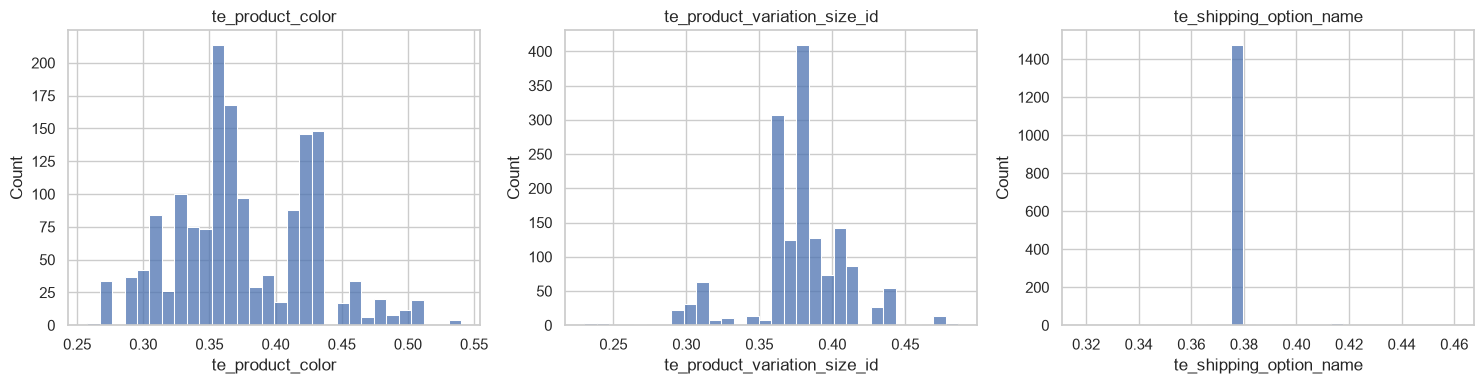

In [7]:
te_cols = [c for c in encoded.columns if c.startswith("te_")]
if te_cols:
    fig, ax = plt.subplots(1, len(te_cols), figsize=(5 * len(te_cols), 4), squeeze=False)
    for a, c in zip(ax[0], te_cols):
        sns.histplot(encoded[c], bins=30, ax=a, color="#4c72b0"); a.set_title(c)
    plt.tight_layout(); plt.show()

## 5. Save outputs

In [8]:
out = pd.concat([df, encoded], axis=1)
out_path = PROC / "womens_clothing_high_cardinality_encoded.csv"
out.to_csv(out_path, index=False)

plan_out.assign(naive_width=naive_width, engineered_width=encoded.shape[1]).to_csv(REPORTS / "task_18_encoding_plan.csv", index=False)
(pd.concat(te_maps, ignore_index=True)[["column", "level", "n", "te_value", "global_mean"]] if te_maps else pd.DataFrame(columns=["column", "level", "n", "te_value", "global_mean"])
 ).to_csv(REPORTS / "task_18_target_encoding_map.csv", index=False)

status = pd.DataFrame([{
    "task": "Task 18 - Categorical Encoding (high cardinality)", "status": "completed",
    "run_at": datetime.now().isoformat(timespec="seconds"), "input_file": src.name,
    "rows_in": len(df), "rows_out": len(out), "target": target_name, "columns_encoded": len(cand),
    "naive_onehot_width": naive_width, "engineered_width": encoded.shape[1],
    "cv_auc_naive": round(auc_naive.mean(), 4), "cv_auc_engineered": round(auc_eng.mean(), 4),
    "output_dataset": out_path.name}])
status.to_csv(REPORTS / "task_18_analysis_status.csv", index=False)
status.T

,0
task,Task 18 - Categorical Encoding (high cardinality)
status,completed
run_at,2026-11-23T16:51:56
input_file,womens_clothing_engagement_features.csv
rows_in,1539
rows_out,1539
target,Rating >= 4
columns_encoded,7
naive_onehot_width,236
engineered_width,33
